# matplotlib 으로 데이터 시각화 해보기
데이터: [UCR ECG5000](https://timeseriesclassification.com/description.php?Dataset=ECG5000) ([Zenodo 배포본](https://zenodo.org/records/11186692)) 를 사용하여 matplotlib에 익숙해지는 연습하기\
따라서 데이터 준비

In [17]:
from pathlib import Path
from urllib.request import urlretrieve

DATA_DIR = Path('data/ecg5000')
DATA_DIR.mkdir(parents=True, exist_ok=True)
FILE_URL = 'https://zenodo.org/records/11186692/files/ECG5000_TRAIN.ts?download=1'

urlretrieve(FILE_URL, DATA_DIR / 'ECG5000_TRAIN.ts')

(PosixPath('data/ecg5000/ECG5000_TRAIN.ts'),
 <http.client.HTTPMessage at 0x109b50a50>)

# 데이터의 구조 이해하기
사용할 데이터는 ts (time series)포맷을 사용\
총 5개의 라벨이며, (1,2,3,4,5) 중 하나의 값을 가짐. (classLabel)\
1. 정상
2. P-on-T PVC
3. PVC (심실 조기 수축)
4. SP (심실상 조기 박동)
5. UB (분류되지 않음)

seriesLength : 140  (equalLength = true) 으로, 각 ECG는 140개의 값을 가짐

numpy와 pyplot 사용해보기

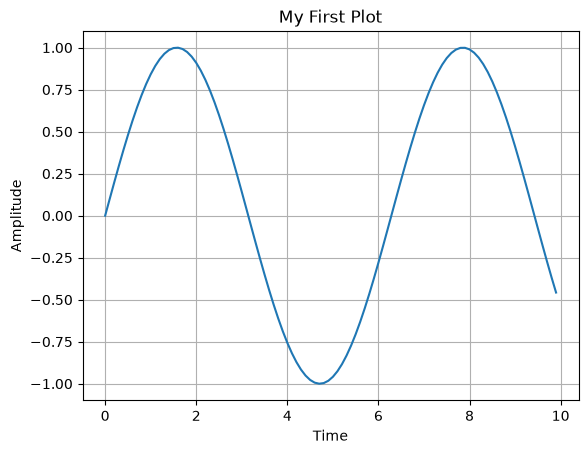

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# 데이터 생성
x = np.arange(0, 10, 0.1)
y = np.sin(x)

# 시각화
plt.plot(x, y)
plt.xlabel("x")
plt.ylabel("y")
plt.title("My First Plot")
plt.grid()
plt.show()

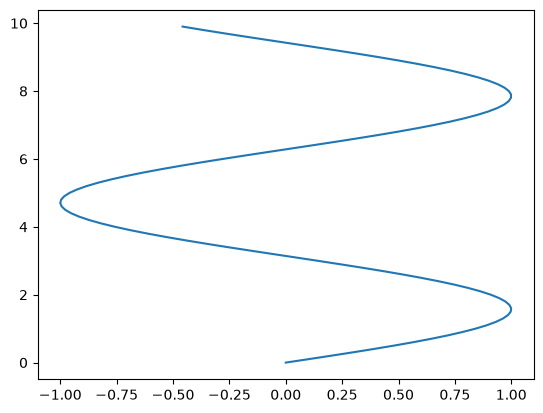

In [8]:
plt.plot(y, x) # 반대로 ?
plt.show()

Text(0, 0.5, 'y')

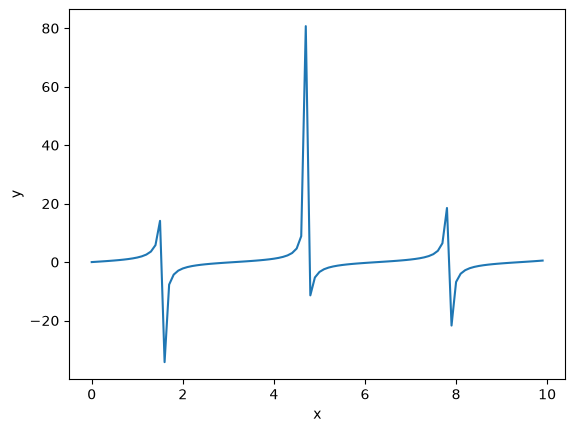

In [9]:
y = np.tan(x)

plt.plot(x,y)
plt.xlabel("x")
plt.ylabel("y")


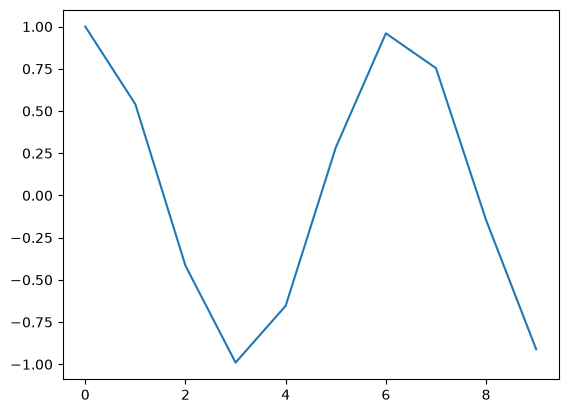

In [14]:
tmp = np.arange(0, 10, 1)
plt.plot(tmp, np.cos(tmp))
plt.show()

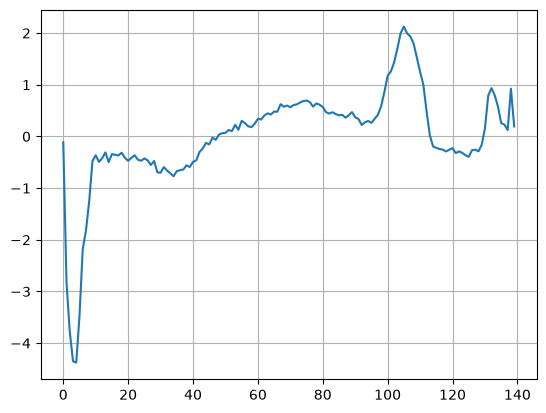

In [26]:
filePath = Path(DATA_DIR / 'ECG5000_TRAIN.ts')
with filePath.open() as file:
    for line in file:
        if line.strip() == "@data":
            break
    data = next(file)
valuesStr, label = data.split(":")
values = [float(x) for x in valuesStr.split(",")]

x = np.arange(0, 140, 1)
y = values

plt.plot(x, y)
plt.grid()
plt.show()